# Tugas  — Latihan Mandiri
## Pertemuan 4: Pengantar Pemrosesan Paralel

Nama: Habil Arrafi  
NIM:  2411511014


## 1. Klasifikasi Flynn

Klasifikasi Flynn digunakan untuk mengelompokkan arsitektur berdasarkan jumlah aliran instruksi dan jumlah aliran data yang diproses secara bersamaan.

| Skenario | Kategori | Alasan |
|---|---|---|
| Operasi `a + arr` pada NumPy array | **SIMD** | Satu operasi/instruksi diterapkan secara serentak pada banyak elemen data. |
| Program Python membaca file lalu memproses baris demi baris | **SISD** | Instruksi diproses secara berurutan terhadap data secara individual. |
| Cluster komputer yang masing-masing melakukan simulasi cuaca berbeda | **MIMD** | Banyak komputer/prosesor menjalankan instruksi yang berbeda terhadap data atau tugas yang berbeda secara independen. |

**Catatan:** Untuk operasi NumPy, klasifikasi SIMD digunakan dalam arti konseptual sesuai materi, yaitu satu operasi vektor diterapkan ke banyak data sekaligus.

In [1]:
import numpy as np

# Contoh konseptual SIMD: satu operasi diterapkan ke seluruh elemen array
a = np.array([1, 2, 3, 4, 5])
arr = np.array([10, 20, 30, 40, 50])

hasil = a + arr

print("a       =", a)
print("arr     =", arr)
print("a + arr =", hasil)
print("\nKlasifikasi konseptual: SIMD")

a       = [1 2 3 4 5]
arr     = [10 20 30 40 50]
a + arr = [11 22 33 44 55]

Klasifikasi konseptual: SIMD


### Penjelasan

Pada contoh tersebut, operasi penjumlahan yang sama diterapkan pada seluruh pasangan elemen array. Karena satu jenis operasi diterapkan pada banyak data secara bersamaan, skenario ini termasuk **SIMD secara konseptual**.

Program Python yang membaca file dan memproses baris satu per satu lebih sesuai dengan **SISD**, sedangkan cluster yang mengerjakan beberapa simulasi berbeda secara independen termasuk **MIMD**.

## 2. Analisis Hukum Amdahl

Diketahui proporsi program yang dapat diparalelkan:

\[
P = 0.85
\]

Rumus Hukum Amdahl:

\[
S(N) = \frac{1}{(1-P)+\frac{P}{N}}
\]

Perhitungan dilakukan untuk jumlah prosesor **N = 2, 4, 8, 16, dan 64**.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

P = 0.85
N_values = np.array([2, 4, 8, 16, 64])

def amdahl_speedup(P, N):
    return 1 / ((1 - P) + P / N)

speedups = np.array([amdahl_speedup(P, N) for N in N_values])

print(f"P = {P}")
print("Hasil speedup:")
for N, S in zip(N_values, speedups):
    print(f"N = {N:>2} -> S(N) = {S:.4f}x")

P = 0.85
Hasil speedup:
N =  2 -> S(N) = 1.7391x
N =  4 -> S(N) = 2.7586x
N =  8 -> S(N) = 3.9024x
N = 16 -> S(N) = 4.9231x
N = 64 -> S(N) = 6.1244x


### Hasil Analisis

Dengan **P = 0,85**, bagian program yang tidak dapat diparalelkan adalah:

\[
1-P = 0.15
\]

Speedup meningkat ketika jumlah prosesor bertambah, tetapi peningkatannya semakin kecil. Hal ini terjadi karena bagian serial sebesar 15% tetap harus dikerjakan secara berurutan.

Batas maksimum ketika jumlah prosesor mendekati tak hingga adalah:

\[
S_{max} = \frac{1}{1-P}
= \frac{1}{0.15}
\approx 6.67
\]

Jadi, meskipun jumlah prosesor terus ditambah, speedup menurut Hukum Amdahl tidak dapat melebihi sekitar **6,67×**.

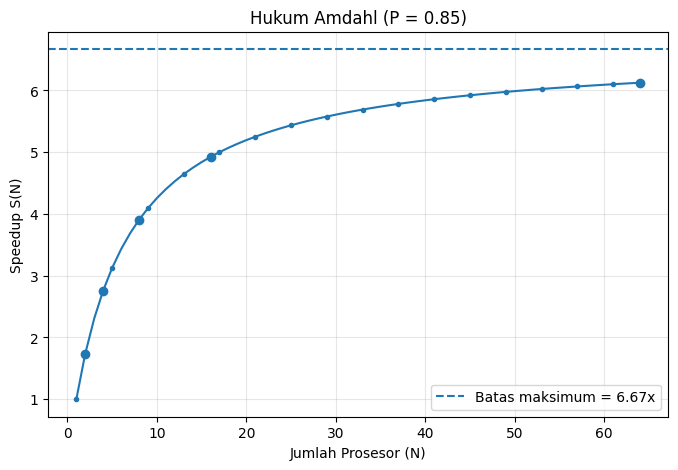

In [3]:
# Plot speedup terhadap jumlah prosesor
N_plot = np.arange(1, 65)
S_plot = amdahl_speedup(P, N_plot)

plt.figure(figsize=(8, 5))
plt.plot(N_plot, S_plot, marker="o", markersize=3, markevery=4)
plt.scatter(N_values, speedups)
plt.axhline(1/(1-P), linestyle="--", label=f"Batas maksimum = {1/(1-P):.2f}x")

plt.title("Hukum Amdahl (P = 0.85)")
plt.xlabel("Jumlah Prosesor (N)")
plt.ylabel("Speedup S(N)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Apakah penambahan prosesor selalu meningkatkan performa?

Tidak selalu memberikan manfaat yang besar. Pada awalnya, penambahan prosesor meningkatkan speedup secara cukup signifikan. Namun, setelah jumlah prosesor semakin banyak, keuntungan tambahan menjadi semakin kecil karena 15% bagian program yang bersifat serial menjadi pembatas.

Dengan demikian, penambahan prosesor setelah titik tertentu dapat memberikan **diminishing returns**, yaitu tambahan sumber daya semakin sedikit menghasilkan peningkatan performa.

## 3. Benchmark Mandiri — Beban CPU (*CPU-bound*)

Untuk benchmarking digunakan fungsi komputasi CPU-bound sederhana yang menghitung jumlah kuadrat bilangan dari 1 sampai `n`. Fungsi ini sengaja menggunakan perulangan Python sehingga membutuhkan kerja CPU dan tidak bergantung pada input/output.

Pengukuran dilakukan menggunakan `time.perf_counter()` dan `timeit`. Nilai waktu dapat berbeda pada setiap komputer karena spesifikasi perangkat, beban sistem, dan kondisi eksekusi.

In [4]:
import time
import timeit

def cpu_bound_task(n):
    total = 0
    for i in range(1, n + 1):
        total += i * i
    return total

N = 5_000_000

# Benchmark menggunakan time.perf_counter()
start = time.perf_counter()
hasil = cpu_bound_task(N)
elapsed = time.perf_counter() - start

print(f"Hasil perhitungan untuk N={N:,}: {hasil:,}")
print(f"Waktu eksekusi: {elapsed:.4f} detik")

Hasil perhitungan untuk N=5,000,000: 41,666,679,166,667,500,000
Waktu eksekusi: 0.2327 detik


In [5]:
# Benchmark berulang menggunakan timeit
jumlah_pengulangan = 5

waktu = timeit.repeat(
    stmt="cpu_bound_task(N)",
    globals=globals(),
    number=1,
    repeat=jumlah_pengulangan
)

print("Waktu 5 pengulangan (detik):")
print([f"{t:.4f}" for t in waktu])
print(f"Waktu terbaik : {min(waktu):.4f} detik")
print(f"Waktu rata-rata: {sum(waktu)/len(waktu):.4f} detik")

Waktu 5 pengulangan (detik):
['0.2392', '0.2225', '0.2315', '0.2277', '0.2305']
Waktu terbaik : 0.2225 detik
Waktu rata-rata: 0.2303 detik


### Perbandingan `time.perf_counter()` dan `timeit`

`time.perf_counter()` cocok untuk mengukur durasi suatu bagian program secara langsung. Sementara itu, `timeit` memudahkan pengulangan pengukuran sehingga hasil benchmarking dapat dibandingkan dengan lebih stabil.

Hasil waktu pada notebook ini **tidak dianggap sebagai angka yang mutlak**, karena waktu eksekusi akan bergantung pada komputer yang digunakan saat notebook dijalankan.

N =  10,000 -> 0.000565 detik
N =  20,000 -> 0.000996 detik
N =  40,000 -> 0.001949 detik
N =  80,000 -> 0.004079 detik
N = 160,000 -> 0.007999 detik


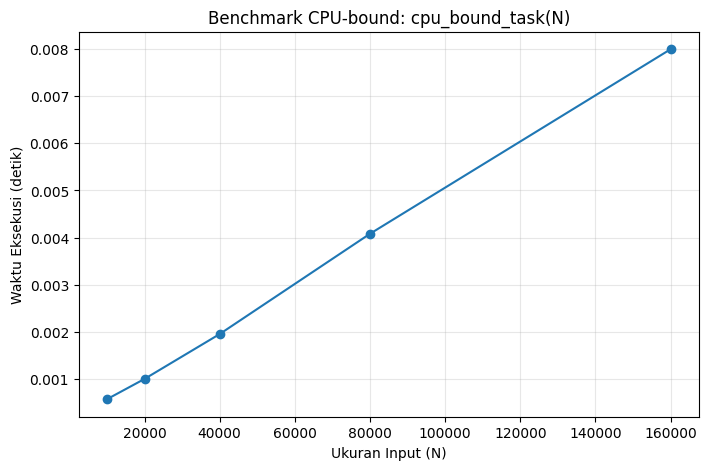

In [6]:
# Benchmark untuk beberapa ukuran input
ukuran_input = [10_000, 20_000, 40_000, 80_000, 160_000]
waktu_eksekusi = []

for n in ukuran_input:
    start = time.perf_counter()
    cpu_bound_task(n)
    waktu = time.perf_counter() - start
    waktu_eksekusi.append(waktu)
    print(f"N = {n:>7,} -> {waktu:.6f} detik")

plt.figure(figsize=(8, 5))
plt.plot(ukuran_input, waktu_eksekusi, marker="o")
plt.title("Benchmark CPU-bound: cpu_bound_task(N)")
plt.xlabel("Ukuran Input (N)")
plt.ylabel("Waktu Eksekusi (detik)")
plt.grid(alpha=0.3)
plt.show()

### Analisis Benchmark

Grafik menunjukkan bahwa waktu eksekusi cenderung meningkat ketika ukuran input `N` bertambah. Hal ini sesuai dengan karakteristik fungsi yang melakukan perulangan terhadap setiap nilai dari 1 sampai `N`.

Karena benchmark menggunakan beban CPU, hasil pengukuran dapat dipengaruhi oleh prosesor, program lain yang sedang berjalan, dan kondisi sistem ketika notebook dieksekusi.

## 4. Refleksi Singkat

**Kapan Hukum Amdahl lebih relevan dibanding Hukum Gustafson, dan sebaliknya?**

Hukum Amdahl lebih relevan ketika ukuran masalah relatif tetap dan ingin diketahui batas speedup akibat penambahan prosesor. Hukum ini menunjukkan bahwa bagian program yang tidak dapat diparalelkan akan membatasi peningkatan performa. Sebaliknya, Hukum Gustafson lebih relevan ketika jumlah prosesor bertambah dan ukuran masalah juga dapat diperbesar. Dalam kondisi tersebut, lebih banyak prosesor dapat digunakan untuk menyelesaikan masalah yang lebih besar dalam waktu yang relatif sama. Jadi, Amdahl cocok untuk melihat batas percepatan pada masalah tetap, sedangkan Gustafson lebih sesuai untuk menganalisis *scaled workload* yang bertambah seiring sumber daya komputasi.

## Kesimpulan

1. Klasifikasi Flynn membantu membedakan pola pemrosesan berdasarkan jumlah aliran instruksi dan data.
2. Hukum Amdahl menunjukkan bahwa bagian serial membatasi speedup maksimum, sehingga penambahan prosesor tidak selalu menghasilkan peningkatan performa yang sebanding.
3. Benchmarking dengan `perf_counter()` dan `timeit` dapat digunakan untuk mengukur waktu eksekusi dan melihat hubungan antara ukuran input dengan beban CPU.
